In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# -----------------------------
# Plot settings
# -----------------------------

OUT_DIR = Path("figures")
OUT_DIR.mkdir(exist_ok=True)

plt.rcParams.update(
    {
        "figure.dpi": 150,
        "savefig.dpi": 300,
        "font.size": 11,
        "axes.labelsize": 11,
        "axes.titlesize": 12,
        "legend.fontsize": 9,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    }
)

zones = ["NO1", "NO2", "NO3", "NO4"]

main_models = [
    "Baseline Median",
    "Baseline Shifted",
    "QRNN",
    "BNN",
]

competition_models = [
    "EquiWindNerds",
    "Knowit",
    "WindSight",
]

all_test_models = main_models + competition_models

split_order = ["Train (now.)", "Val (now.)", "Val", "Test"]

model_colors = {
    "Baseline Median": "#999999",
    "Baseline Shifted": "#666666",
    "QRNN": "#0072B2",
    "BNN": "#D55E00",
    "EquiWindNerds": "#009E73",
    "Knowit": "#CC79A7",
    "WindSight": "#56B4E9",
}

In [3]:
# -----------------------------
# Daten
# -----------------------------

data = [
    # Model, Split, Zone, RMSE, CRPS
    ("Baseline Median", "Train (now.)", "NO1", 99.11, 77.01),
    ("Baseline Median", "Train (now.)", "NO2", 412.79, 345.77),
    ("Baseline Median", "Train (now.)", "NO3", 526.63, 432.07),
    ("Baseline Median", "Train (now.)", "NO4", 235.70, 195.02),
    ("Baseline Median", "Val (now.)", "NO1", 144.56, 112.63),
    ("Baseline Median", "Val (now.)", "NO2", 394.92, 330.16),
    ("Baseline Median", "Val (now.)", "NO3", 561.72, 472.35),
    ("Baseline Median", "Val (now.)", "NO4", 249.96, 205.83),
    ("Baseline Median", "Val", "NO1", 143.57, 112.45),
    ("Baseline Median", "Val", "NO2", 380.48, 319.12),
    ("Baseline Median", "Val", "NO3", 572.60, 481.83),
    ("Baseline Median", "Val", "NO4", 258.25, 213.14),
    ("Baseline Median", "Test", "NO1", 138.42, 105.08),
    ("Baseline Median", "Test", "NO2", 571.11, 536.09),
    ("Baseline Median", "Test", "NO3", 355.00, 267.34),
    ("Baseline Median", "Test", "NO4", 266.76, 219.91),
    ("Baseline Shifted", "Train (now.)", "NO1", 119.34, 91.07),
    ("Baseline Shifted", "Train (now.)", "NO2", 534.90, 418.44),
    ("Baseline Shifted", "Train (now.)", "NO3", 635.06, 492.73),
    ("Baseline Shifted", "Train (now.)", "NO4", 290.43, 230.30),
    ("Baseline Shifted", "Val (now.)", "NO1", 167.49, 133.23),
    ("Baseline Shifted", "Val (now.)", "NO2", 588.50, 470.12),
    ("Baseline Shifted", "Val (now.)", "NO3", 700.66, 565.94),
    ("Baseline Shifted", "Val (now.)", "NO4", 281.60, 228.44),
    ("Baseline Shifted", "Val", "NO1", 170.00, 136.48),
    ("Baseline Shifted", "Val", "NO2", 557.16, 440.33),
    ("Baseline Shifted", "Val", "NO3", 689.66, 550.36),
    ("Baseline Shifted", "Val", "NO4", 283.47, 231.07),
    ("Baseline Shifted", "Test", "NO1", 136.25, 108.72),
    ("Baseline Shifted", "Test", "NO2", 483.71, 405.60),
    ("Baseline Shifted", "Test", "NO3", 556.52, 450.56),
    ("Baseline Shifted", "Test", "NO4", 306.85, 253.14),
    ("QRNN", "Train (now.)", "NO1", 52.71, 26.04),
    ("QRNN", "Train (now.)", "NO2", 105.85, 55.16),
    ("QRNN", "Train (now.)", "NO3", 178.23, 86.44),
    ("QRNN", "Train (now.)", "NO4", 88.50, 45.34),
    ("QRNN", "Val (now.)", "NO1", 69.93, 37.17),
    ("QRNN", "Val (now.)", "NO2", 97.67, 50.42),
    ("QRNN", "Val (now.)", "NO3", 196.31, 98.02),
    ("QRNN", "Val (now.)", "NO4", 86.57, 49.84),
    ("QRNN", "Val", "NO1", 68.68, 37.09),
    ("QRNN", "Val", "NO2", 141.97, 77.56),
    ("QRNN", "Val", "NO3", 235.78, 126.23),
    ("QRNN", "Val", "NO4", 114.71, 63.49),
    ("QRNN", "Test", "NO1", 76.55, 38.53),
    ("QRNN", "Test", "NO2", 188.50, 100.73),
    ("QRNN", "Test", "NO3", 397.13, 210.30),
    ("QRNN", "Test", "NO4", 122.80, 71.11),
    ("BNN", "Train (now.)", "NO1", 44.82, 22.16),
    ("BNN", "Train (now.)", "NO2", 93.93, 47.65),
    ("BNN", "Train (now.)", "NO3", 165.05, 79.14),
    ("BNN", "Train (now.)", "NO4", 73.51, 39.02),
    ("BNN", "Val (now.)", "NO1", 66.98, 35.20),
    ("BNN", "Val (now.)", "NO2", 95.45, 49.91),
    ("BNN", "Val (now.)", "NO3", 196.53, 101.39),
    ("BNN", "Val (now.)", "NO4", 86.36, 48.46),
    ("BNN", "Val", "NO1", 67.94, 35.61),
    ("BNN", "Val", "NO2", 148.88, 75.03),
    ("BNN", "Val", "NO3", 231.47, 123.55),
    ("BNN", "Val", "NO4", 112.07, 61.96),
    ("BNN", "Test", "NO1", 60.11, 30.82),
    ("BNN", "Test", "NO2", 204.72, 110.92),
    ("BNN", "Test", "NO3", 388.94, 211.57),
    ("BNN", "Test", "NO4", 121.98, 67.92),
]

df = pd.DataFrame(data, columns=["Model", "Split", "Zone", "RMSE", "CRPS"])

# Competition models nur Test / RMSE
competition_data = [
    ("EquiWindNerds", "Test", "NO1", 61.53, np.nan),
    ("EquiWindNerds", "Test", "NO2", 184.71, np.nan),
    ("EquiWindNerds", "Test", "NO3", 350.93, np.nan),
    ("EquiWindNerds", "Test", "NO4", 108.77, np.nan),
    ("Knowit", "Test", "NO1", 69.77, np.nan),
    ("Knowit", "Test", "NO2", 189.61, np.nan),
    ("Knowit", "Test", "NO3", 362.15, np.nan),
    ("Knowit", "Test", "NO4", 131.82, np.nan),
    ("WindSight", "Test", "NO1", 74.35, np.nan),
    ("WindSight", "Test", "NO2", 179.22, np.nan),
    ("WindSight", "Test", "NO3", 368.77, np.nan),
    ("WindSight", "Test", "NO4", 115.61, np.nan),
]

df_comp = pd.DataFrame(
    competition_data, columns=["Model", "Split", "Zone", "RMSE", "CRPS"]
)

df_all = pd.concat([df, df_comp], ignore_index=True)
zones = ["NO1", "NO2", "NO3", "NO4"]
models = [
    "Baseline Median",
    "Baseline Shifted",
    "QRNN",
    "BNN",
    "EquiWindNerds",
    "Knowit",
    "WindSight",
]

test_df = df_all[df_all["Split"] == "Test"]

In [4]:
average_data = [
    # Model, Split, Zone, RMSE, CRPS
    ("Baseline Median", "Train (now.)", "Average", 356.89, 259.41),
    ("Baseline Median", "Val (now.)", "Average", 372.42, 280.18),
    ("Baseline Median", "Val", "Average", 374.14, 281.58),
    ("Baseline Median", "Test", "Average", 364.99, 278.89),
    ("Baseline Shifted", "Train (now.)", "Average", 439.76, 302.80),
    ("Baseline Shifted", "Val (now.)", "Average", 485.65, 349.11),
    ("Baseline Shifted", "Val", "Average", 472.81, 339.24),
    ("Baseline Shifted", "Test", "Average", 404.00, 303.23),
    ("QRNN", "Train (now.)", "Average", 116.55, 53.35),
    ("QRNN", "Val (now.)", "Average", 122.97, 58.87),
    ("QRNN", "Val", "Average", 153.00, 76.09),
    ("QRNN", "Test", "Average", 231.89, 105.22),
    ("BNN", "Train (now.)", "Average", 105.16, 47.05),
    ("BNN", "Val (now.)", "Average", 122.63, 58.87),
    ("BNN", "Val", "Average", 152.47, 74.15),
    ("BNN", "Test", "Average", 226.92, 102.40),
    ("EquiWindNerds", "Test", "Average", 207.90, np.nan),
    ("Knowit", "Test", "Average", 217.57, np.nan),
    ("WindSight", "Test", "Average", 216.22, np.nan),
]

df_avg = pd.DataFrame(average_data, columns=["Model", "Split", "Zone", "RMSE", "CRPS"])

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# -----------------------------
# Settings
# -----------------------------

OUT_DIR = Path("figures")
OUT_DIR.mkdir(exist_ok=True)

zones = ["NO1", "NO2", "NO3", "NO4"]

split_order = ["Train (now.)", "Val (now.)", "Val", "Test"]

main_models = [
    "Baseline Median",
    "Baseline Shifted",
    "QRNN",
    "BNN",
]

competition_models = [
    "EquiWindNerds",
    "Knowit",
    "WindSight",
]

all_models = main_models + competition_models

split_colors = {
    "Train (now.)": "#1f77b4",
    "Val (now.)": "#2ca02c",
    "Val": "#ff7f0e",
    "Test": "#CC79A7",
}

plt.rcParams.update(
    {
        "figure.dpi": 150,
        "savefig.dpi": 300,
        "font.size": 11,
        "axes.labelsize": 11,
        "axes.titlesize": 12,
        "legend.fontsize": 9,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    }
)


def plot_metric_all_models(df_all, metric="RMSE"):
    bar_width = 0.18
    bar_gap = 0.0
    model_gap = 0.2

    for zone in zones:
        zone_df = df_all[df_all["Zone"] == zone]

        fig, ax = plt.subplots(figsize=(8.5, 4.5))

        x_cursor = 0.0
        xtick_positions = []
        xtick_labels = []

        for model in all_models:
            model_df = zone_df[zone_df["Model"] == model]

            splits_present = [
                split for split in split_order if split in model_df["Split"].values
            ]

            bar_positions = []

            for split in splits_present:
                value = model_df.loc[model_df["Split"] == split, metric].values[0]

                if np.isnan(value):
                    continue

                ax.bar(
                    x_cursor,
                    value,
                    width=bar_width,
                    color=split_colors[split],
                    edgecolor="black",
                    linewidth=0.4,
                )

                bar_positions.append(x_cursor)
                x_cursor += bar_width + bar_gap

            if bar_positions:
                xtick_positions.append(np.mean(bar_positions))
                xtick_labels.append(model)

            x_cursor += model_gap

        # Legend
        for split in split_order:
            ax.bar(
                0,
                0,
                width=bar_width,
                color=split_colors[split],
                edgecolor="black",
                linewidth=0.4,
                label=split,
            )

        ax.set_xticks(xtick_positions)
        ax.set_xticklabels(xtick_labels, rotation=25, ha="right")

        ax.set_ylabel(metric)
        ax.set_title(f"{metric} by split and model in {zone}")

        ax.grid(axis="y", alpha=0.25)
        ax.legend(title="Split", ncol=2)

        fig.tight_layout()

        # fig.savefig(
        #     OUT_DIR / f"{metric.lower()}_all_models_{zone}.pdf",
        #     bbox_inches="tight",
        # )
        # fig.savefig(
        #     OUT_DIR / f"{metric.lower()}_all_models_{zone}.png",
        #     bbox_inches="tight",
        # )

        plt.show()

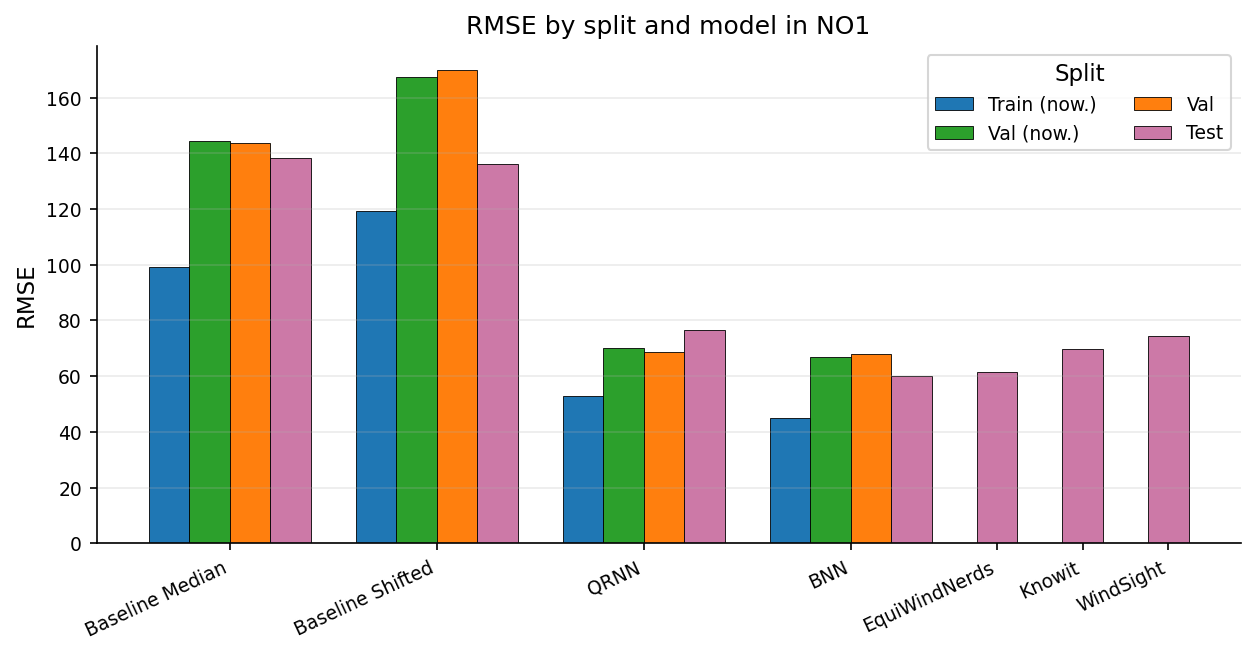

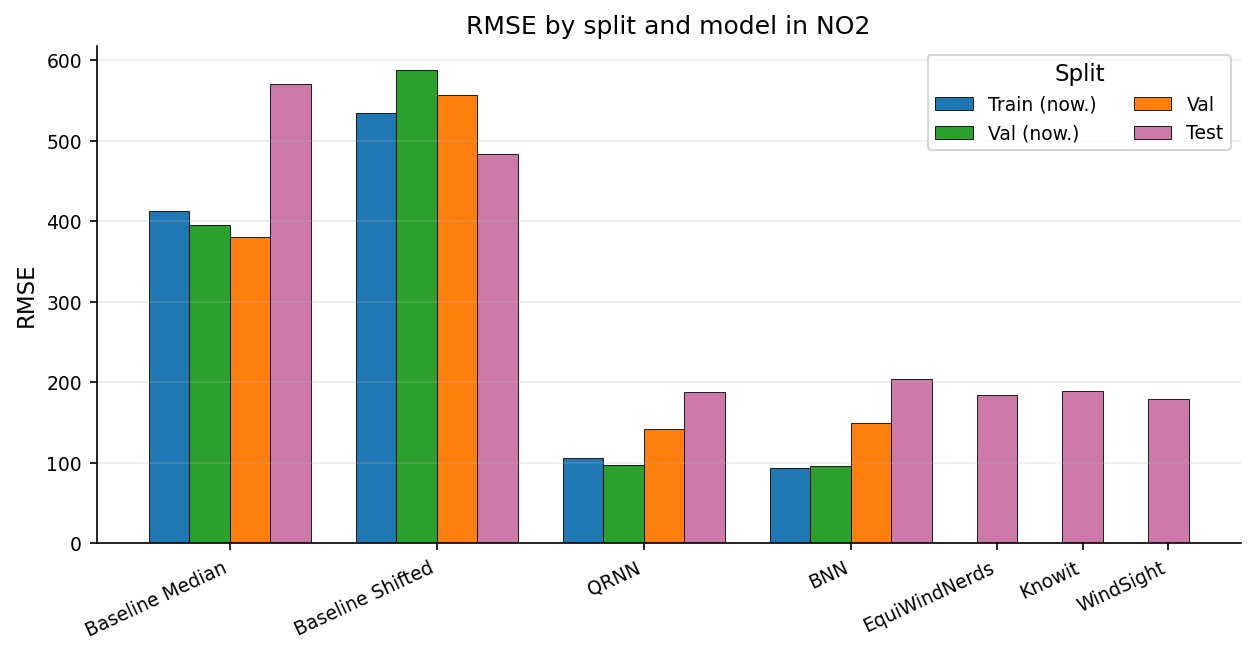

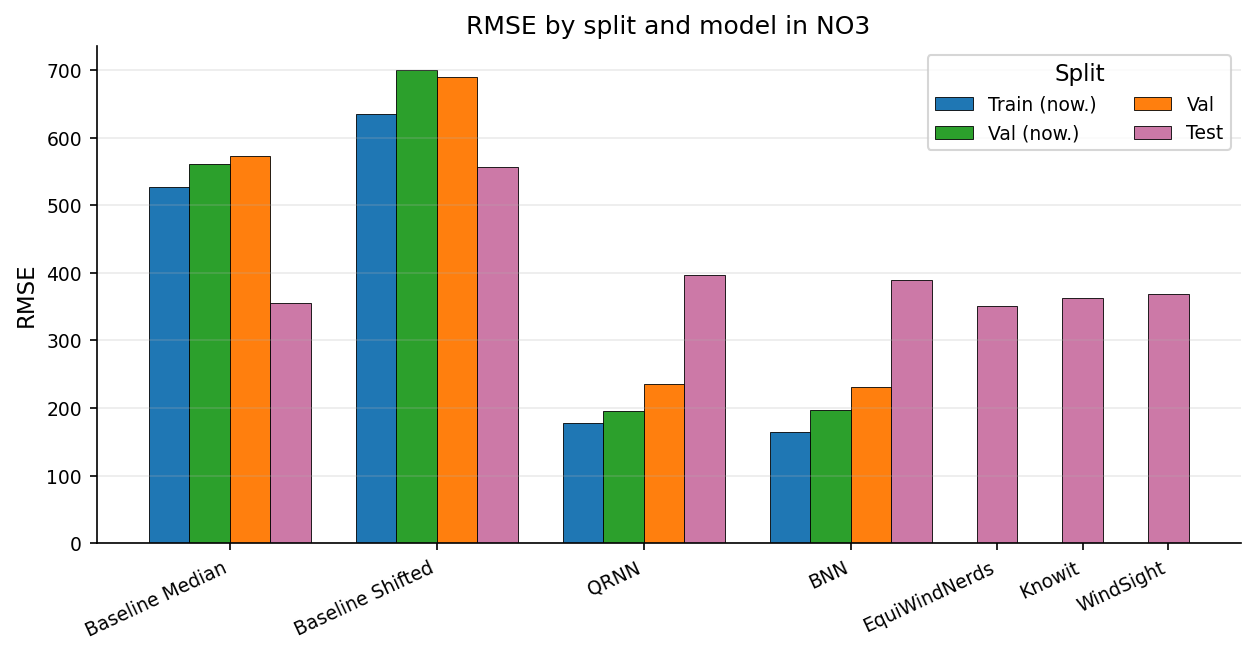

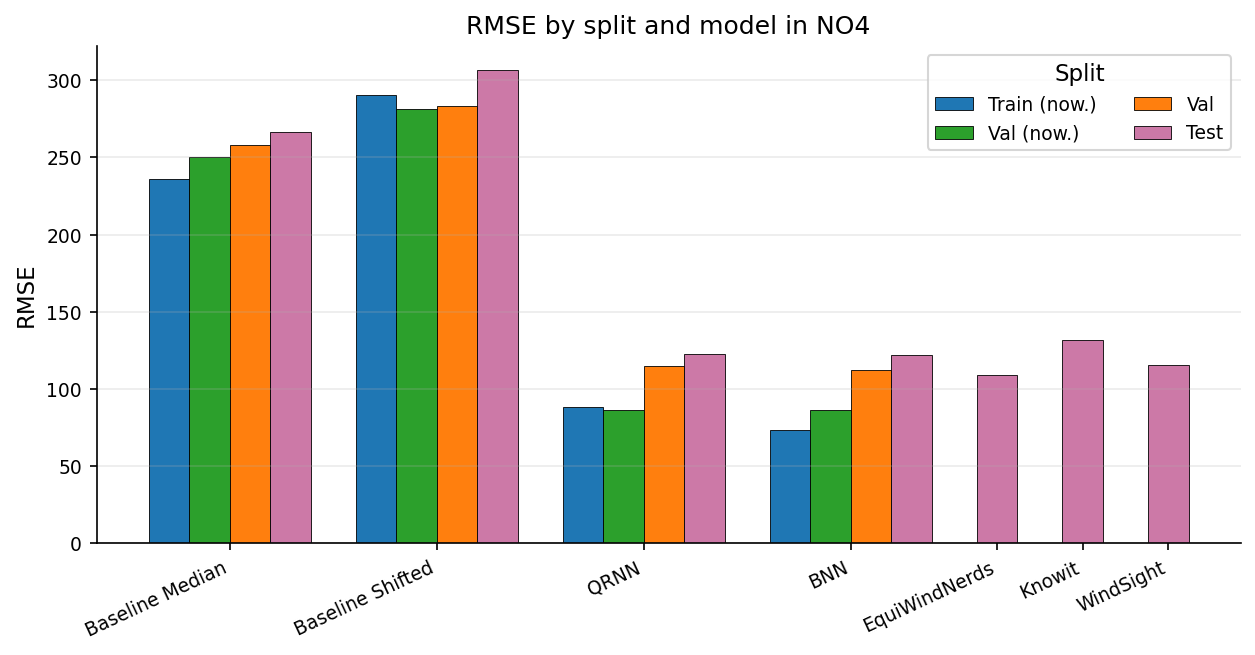

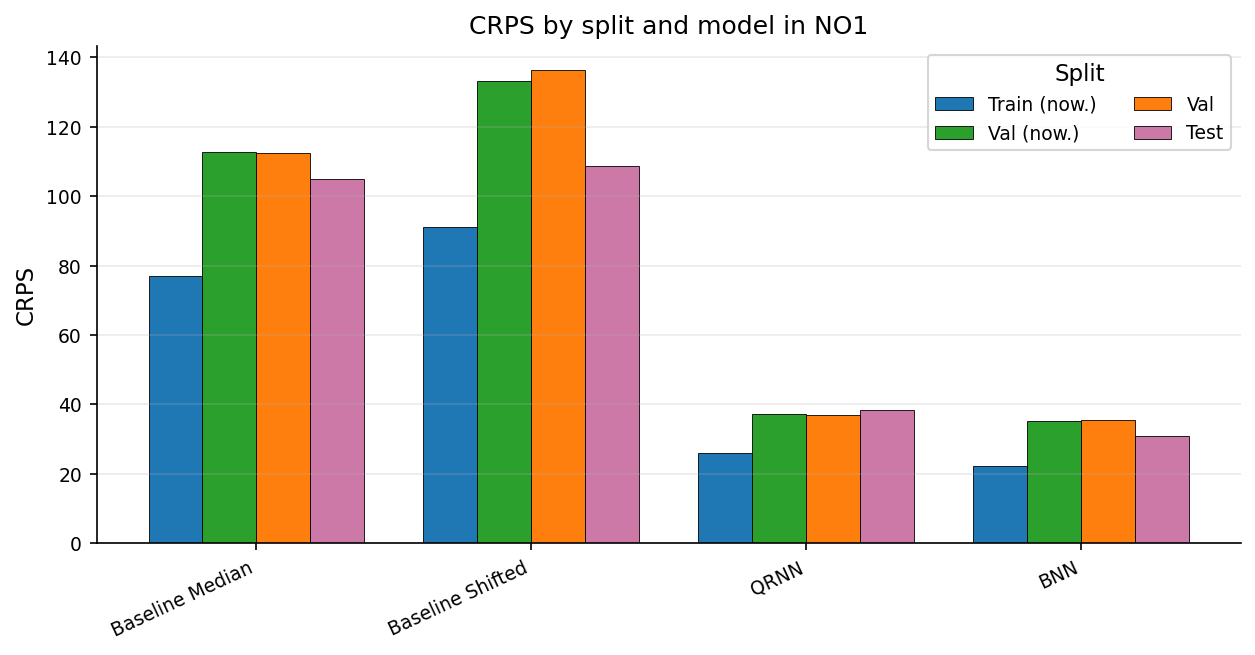

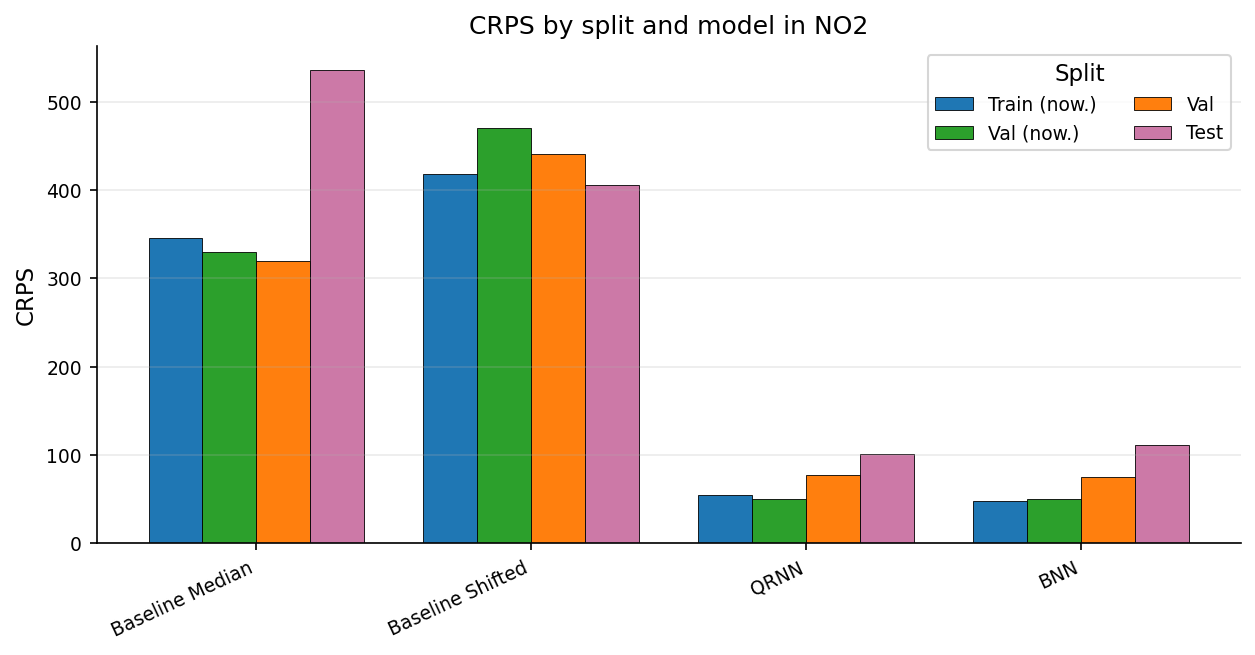

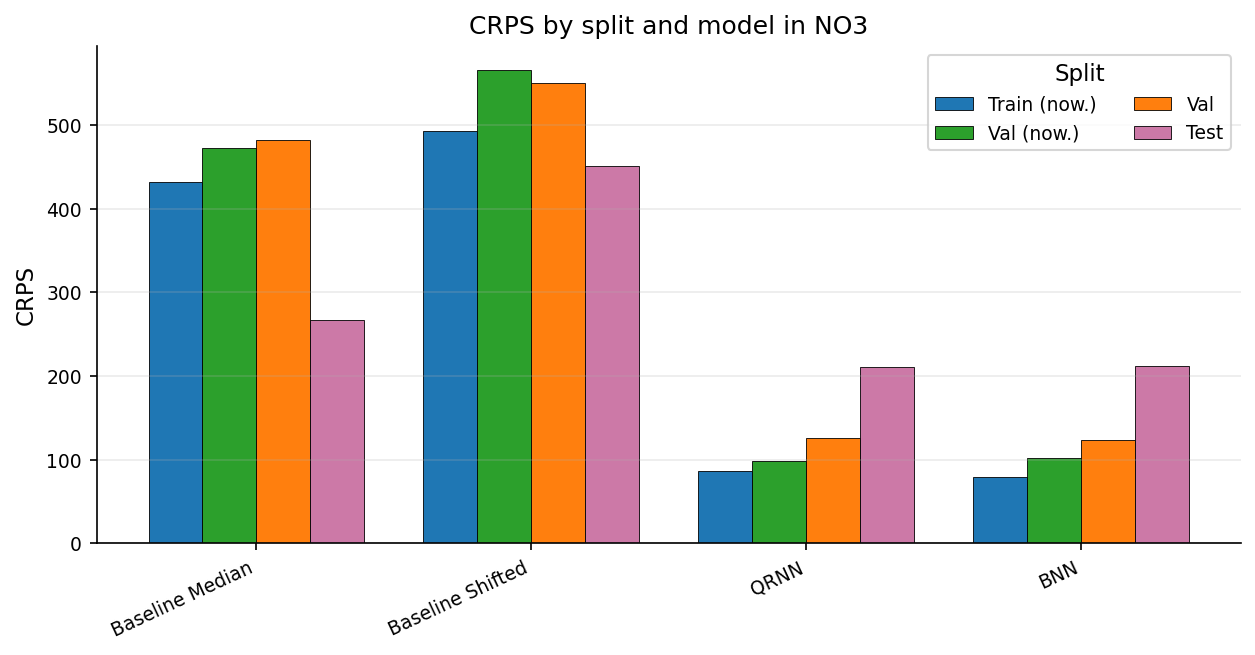

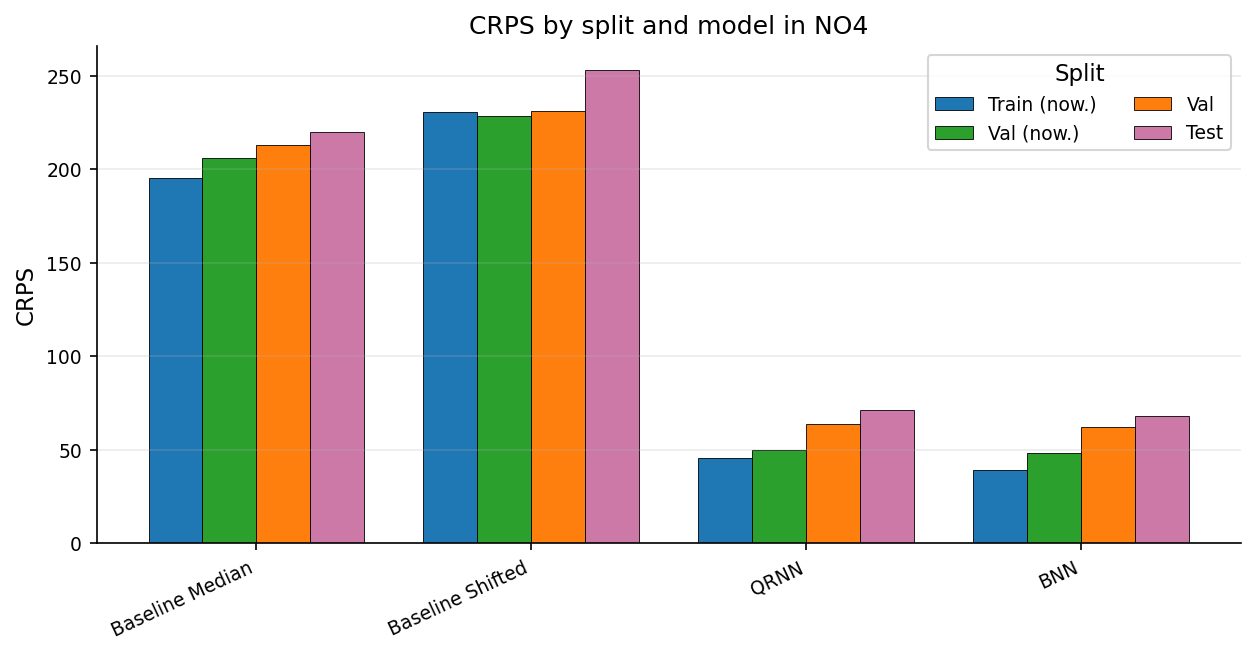

In [55]:
# -----------------------------
# Calls
# -----------------------------

plot_metric_all_models(df_all, metric="RMSE")

# CRPS nur sinnvoll, wenn die Competition-Modelle NaN haben.
# Diese werden automatisch übersprungen.
plot_metric_all_models(df_all, metric="CRPS")

In [8]:
def plot_metric_all_models(df_all, metric="RMSE"):
    bar_width = 0.2
    bar_gap = 0.0
    model_gap = 0.4

    fig, axes = plt.subplots(1, len(zones), figsize=(16, 5), sharey=False)
    # fig, axes = plt.subplots(
    #     1, len(zones),
    #     figsize=(16, 5.5),   # breiter + etwas höher
    #     sharey=False,
    #     gridspec_kw={"wspace": 0.15},  # weniger Abstand zwischen Plots
    # )

    for ax, zone in zip(axes, zones):
        zone_df = df_all[df_all["Zone"] == zone]

        x_cursor = 0.0
        xtick_positions = []
        xtick_labels = []

        for model in all_models:
            model_df = zone_df[zone_df["Model"] == model]

            splits_present = [
                split for split in split_order if split in model_df["Split"].values
            ]

            bar_positions = []

            for split in splits_present:
                value = model_df.loc[model_df["Split"] == split, metric].values[0]

                if np.isnan(value):
                    continue

                ax.bar(
                    x_cursor,
                    value,
                    width=bar_width,
                    color=split_colors[split],
                    edgecolor="black",
                    linewidth=0.4,
                )

                bar_positions.append(x_cursor)
                x_cursor += bar_width + bar_gap

            if bar_positions:
                xtick_positions.append(np.mean(bar_positions))
                xtick_labels.append(model)

            x_cursor += model_gap

        ax.set_xticks(xtick_positions)
        ax.set_xticklabels(xtick_labels, rotation=45, ha="right", fontsize=12)

        ax.set_title(zone, fontsize=16)
        ax.grid(axis="y", alpha=0.25)

    # Gemeinsame Labels
    axes[0].set_ylabel(metric, fontsize=12)

    # Legend (nur einmal global)
    handles = [
        plt.Rectangle((0, 0), 1, 1, color=split_colors[s], ec="black", lw=0.4)
        for s in split_order
    ]
    # fig.legend(handles, split_order, title="Split", ncol=2, loc="upper center")
    axes[-1].legend(
        handles,
        split_order,
        title="Split",
        loc="upper right",
        # bbox_to_anchor=(1.02, 1),  # rechts außerhalb des letzten Subplots
        borderaxespad=0,
        fontsize=12,
    )
    # ax.set_title(f"RMSE Across Models and Data Splits ({zone})")
    # fig.tight_layout(rect=[0, 0, 1, 0.9])
    # fig.tight_layout(rect=[0, 0.08, 1, 0.9])
    fig.tight_layout(rect=[0, 0.1, 1, 0.92])
    fig.suptitle(f"{metric} Across Models and Data Splits", fontsize=18)
    # fig.savefig(
    #     f"../plots/{metric.lower()}_all_models_all_zones.pdf", bbox_inches="tight"
    # )
    # fig.savefig(
    #     f"../plots/{metric.lower()}_all_models_all_zones.png", bbox_inches="tight"
    # )

    plt.show()

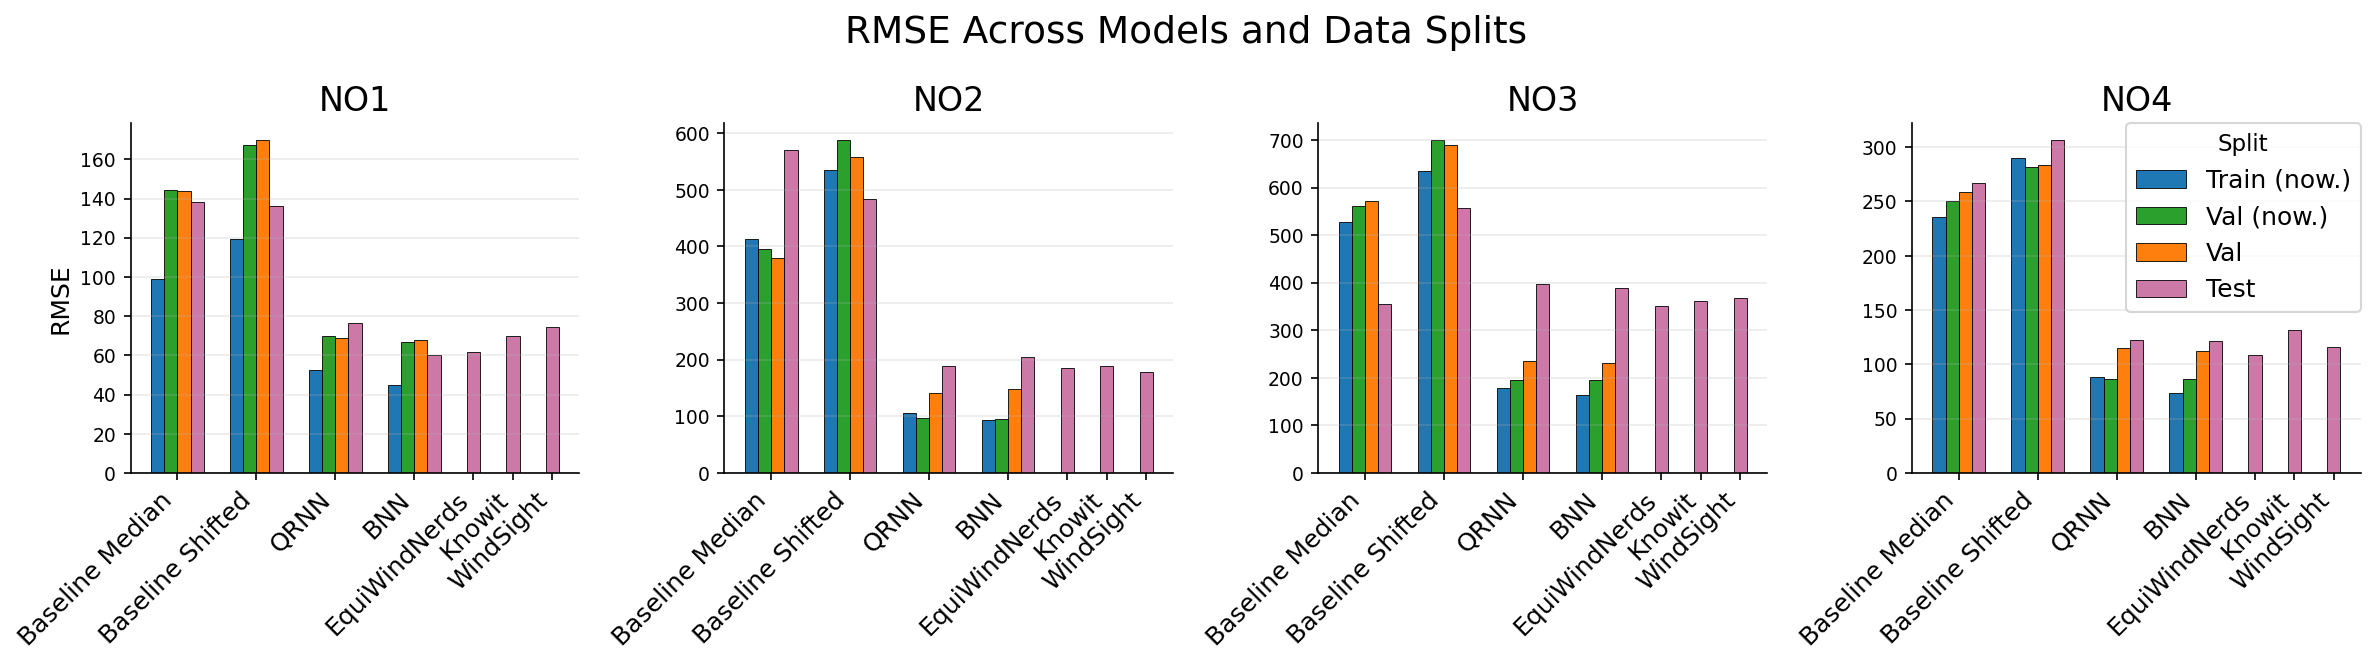

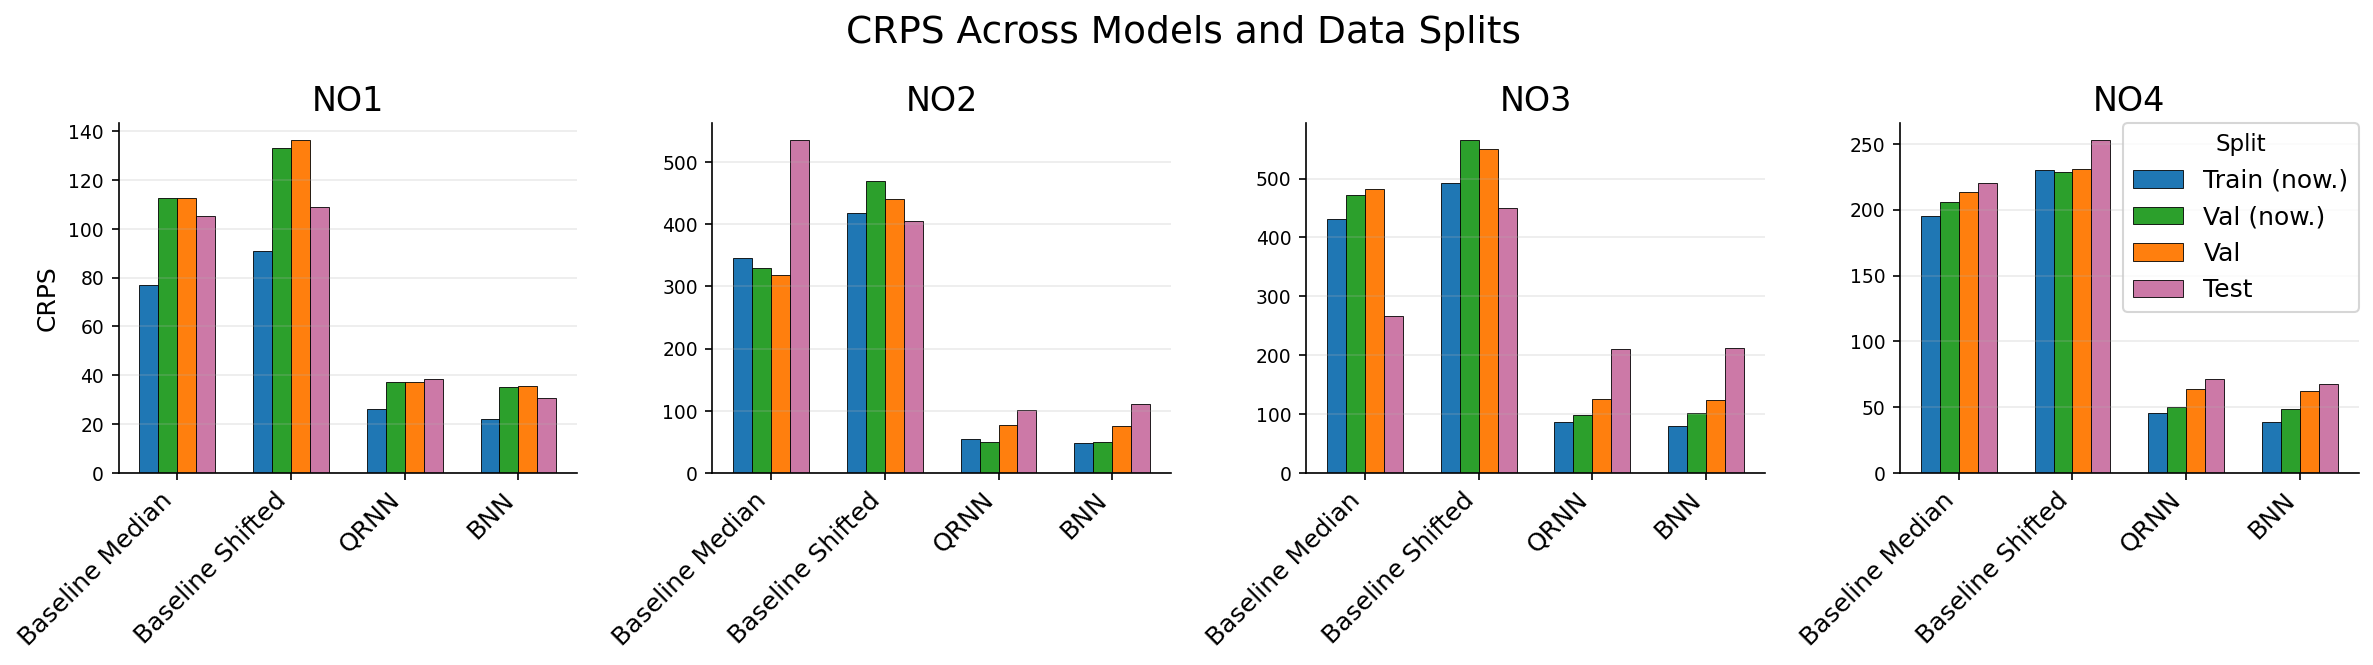

In [9]:
# Calls
# -----------------------------

plot_metric_all_models(df_all, metric="RMSE")

# CRPS nur sinnvoll, wenn die Competition-Modelle NaN haben.
# Diese werden automatisch übersprungen.
plot_metric_all_models(df_all, metric="CRPS")

In [ ]:
def plot_average_metrics(avg_df):
    bar_width = 0.2
    bar_gap = 0.0
    model_gap = 0.4

    metrics = ["RMSE", "CRPS"]

    fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.2), sharey=False)

    for ax, metric in zip(axes, metrics):
        x_cursor = 0.0
        xtick_positions = []
        xtick_labels = []

        for model in all_models:
            model_df = avg_df[avg_df["Model"] == model]

            splits_present = [
                split for split in split_order if split in model_df["Split"].values
            ]

            bar_positions = []

            for split in splits_present:
                value = model_df.loc[model_df["Split"] == split, metric].values[0]

                if np.isnan(value):
                    continue

                ax.bar(
                    x_cursor,
                    value,
                    width=bar_width,
                    color=split_colors[split],
                    edgecolor="black",
                    linewidth=0.4,
                )

                bar_positions.append(x_cursor)
                x_cursor += bar_width + bar_gap

            if bar_positions:
                xtick_positions.append(np.mean(bar_positions))
                xtick_labels.append(model)

            x_cursor += model_gap

        ax.set_xticks(xtick_positions)
        ax.set_xticklabels(xtick_labels, rotation=45, ha="right", fontsize=10)
        ax.set_ylabel(metric, fontsize=11)
        ax.set_title(f"Average {metric}", fontsize=12)
        ax.grid(axis="y", alpha=0.25)

    handles = [
        plt.Rectangle((0, 0), 1, 1, color=split_colors[s], ec="black", lw=0.4)
        for s in split_order
    ]

    axes[-1].legend(
        handles,
        split_order,
        title="Split",
        loc="upper right",
        borderaxespad=0,
        fontsize=10,
    )

    # fig.suptitle("Average Model Performance Across Data Splits", fontsize=18)

    fig.tight_layout(rect=[0, 0, 1, 0.99])

    fig.savefig(
        "../plots/average_rmse_crps_all_models_without_title_font.pdf",
        bbox_inches="tight",
    )

    plt.show()

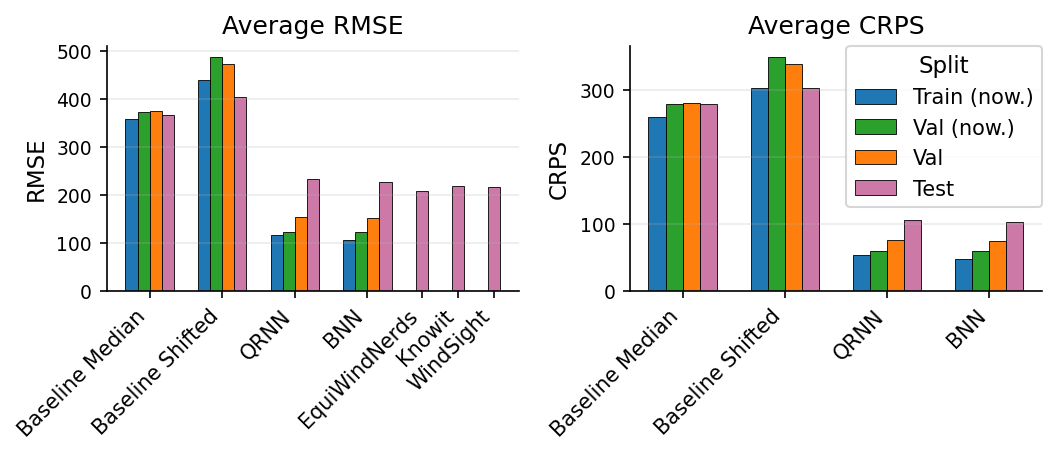

In [18]:
plot_average_metrics(df_avg)